# Bassez et al. 2021 — Breast Cancer (10x) · Step 01: Preprocessing
Malignant cell-state manifold, CCCA meta-atlas protocol (source of truth: Puram2017 reference notebooks).
Autonomous re-run (attempt 4, `-3`). Every tunable choice is **derived from this dataset and shown here**,
not copied from the anchor (02_train C1–C4).

**Gate 1 (mixing + continuity)** is decided on the *regenerated embedding* across a Harmony integration-strength
(`theta`) sweep with a per-neighbourhood metric (iLISI) — never a single scalar (03_eval fork 1). Per-patient
archipelagos and two-blob manifolds are the failure modes to rule out; each density lobe's biology (samples,
cell cycle, signatures) is settled before the GO (03_eval fork 2), and island removal is run to completion.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                     # Bassez2021_Breast-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Breast
data_name = 'Data_' + name.split('-')[0]                 # strip the -3 re-run suffix -> Data_Bassez2021_Breast
pth  = os.path.join(*([os.pardir]*6))                    # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', data_name)

dataset: Bassez2021_Breast-3 | category: Breast | input: Data_Bassez2021_Breast


### Load malignant cells
The loader auto-detects normalisation from the matrix filename (`UMIcounts` → normalize_total), then log1p. We keep only `Malignant` cells, as the protocol scores developmental programs on the malignant compartment.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p normalized UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Bassez2021_Breast
Done.
full atlas: (226635, 22567)
malignant: (65885, 22567) | samples: 42
expression: X max 7.92 (log1p normalized UMI counts)


### Sample threshold — derived by gap-finding
Sort per-sample malignant counts and read the largest ratio gap. Here counts fall smoothly from 6,868 down to 92,
then a single degenerate 3-cell sample (BIOKEY_34). The only real cliff is that 3-cell sample, so a small floor
(`FLOOR=20`) removes only the degenerate sample and keeps every biologically real one — the anchor's `≥100` would
discard 39 valid samples and is not portable at this scale (02_train C4).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample malignant counts:', vals.astype(int).tolist())
print(f'largest ratio gap: {int(vals[gap])} -> {int(vals[gap+1])} (x{ratios[gap]:.1f}) at rank {gap} '
      f'(the lone degenerate sample)')
FLOOR = 20   # min cells for a stable per-sample Harmony centroid; strips only the 3-cell degenerate sample
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'FLOOR = {FLOOR} -> kept {len(keep)}/{len(n)} samples (dropped {sorted(n.index[n < FLOOR].tolist())}); '
      f'{adata.shape[0]} cells; min per-sample = {int(n[n>=FLOOR].min())}')

sorted per-sample malignant counts: [6868, 5650, 4898, 4777, 3336, 3312, 3258, 3164, 3139, 2313, 1996, 1972, 1848, 1837, 1736, 1720, 1417, 1305, 1086, 1050, 977, 908, 826, 796, 666, 600, 580, 556, 542, 415, 377, 288, 276, 253, 223, 223, 194, 174, 133, 101, 92, 3]
largest ratio gap: 92 -> 3 (x30.7) at rank 40 (the lone degenerate sample)
FLOOR = 20 -> kept 41/42 samples (dropped ['BIOKEY_34']); 65882 cells; min per-sample = 92


### Gene filter · overdispersion · PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio[:12]:', np.round(vr[:12], 4).tolist())
cum = np.cumsum(vr)
print('cumulative var @ pcs 20/30/40:', [round(cum[i-1],3) for i in [20,30,40]],
      '-> n_pcs=30 centres the robust 20-40 range (Puram 40 / Kürten 20 precedents)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2498 over-dispersed features (0:00:05) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2498
PCA variance ratio[:12]: [0.1263, 0.0655, 0.0479, 0.0246, 0.0206, 0.0181, 0.0135, 0.0115, 0.0108, 0.0092, 0.0081, 0.0081]
cumulative var @ pcs 20/30/40: [np.float64(0.408), np.float64(0.444), np.float64(0.469)] -> n_pcs=30 centres the robust 20-40 range (Puram 40 / Kürten 20 precedents)


### Gate 1 — integration-strength (theta) sweep with per-neighbourhood iLISI
iLISI = effective number of samples in each cell's neighbourhood (random baseline ≈ #samples). We sweep Harmony
`theta` and read iLISI *and the regenerated embedding*, not a single scalar. This is the fork that failed on
Kürten/Bischoff: the scalar can plateau while the embedding is still a per-patient archipelago or a two-blob
split. Below, iLISI rises pre→post and plateaus over theta 1–10, declining by theta=20 (over-integration).

In [6]:
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
smp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print('random baseline ~ %d effective samples' % nsamp)
for npc in [20, 30, 40]:
    il = ilisi(adata.obsm['X_pca'][:,:npc], smp)
    print(f'PRE-Harmony  n_pcs={npc}: iLISI median={np.median(il):.2f}  p10={np.percentile(il,10):.2f}')
H = {}
for th in [2, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    H[th] = adata.obsm['X_pca_harmony'].copy()
    il = ilisi(H[th][:,:30], smp)
    print(f'theta={th:>2} n_pcs=30: iLISI median={np.median(il):.2f}  p10={np.percentile(il,10):.2f}')

random baseline ~ 41 effective samples
PRE-Harmony  n_pcs=20: iLISI median=5.51  p10=1.33
PRE-Harmony  n_pcs=30: iLISI median=4.92  p10=1.20
PRE-Harmony  n_pcs=40: iLISI median=4.52  p10=1.17
theta= 2 n_pcs=30: iLISI median=8.67  p10=3.08
theta=10 n_pcs=30: iLISI median=8.60  p10=3.23
theta=20 n_pcs=30: iLISI median=8.10  p10=3.16


### Regenerate the embedding at each theta and read continuity off the picture
The scalar is nearly flat across theta, so continuity must be read from the embedding + its connected-component
structure. **theta=2 fragments** (a large fraction of cells detach as small components → an under-integration
archipelago); **theta=10 gives one continuous body** (>99% of cells in a single connected component). This is
exactly why Gate 1 is judged on the regenerated embedding, not the iLISI scalar — the honest integration here is
the stronger one, which *merges* density lobes rather than smoothing over a real second lineage.

theta=2: UMAP radius-graph main component = 0.448 of cells
theta=10: UMAP radius-graph main component = 0.998 of cells


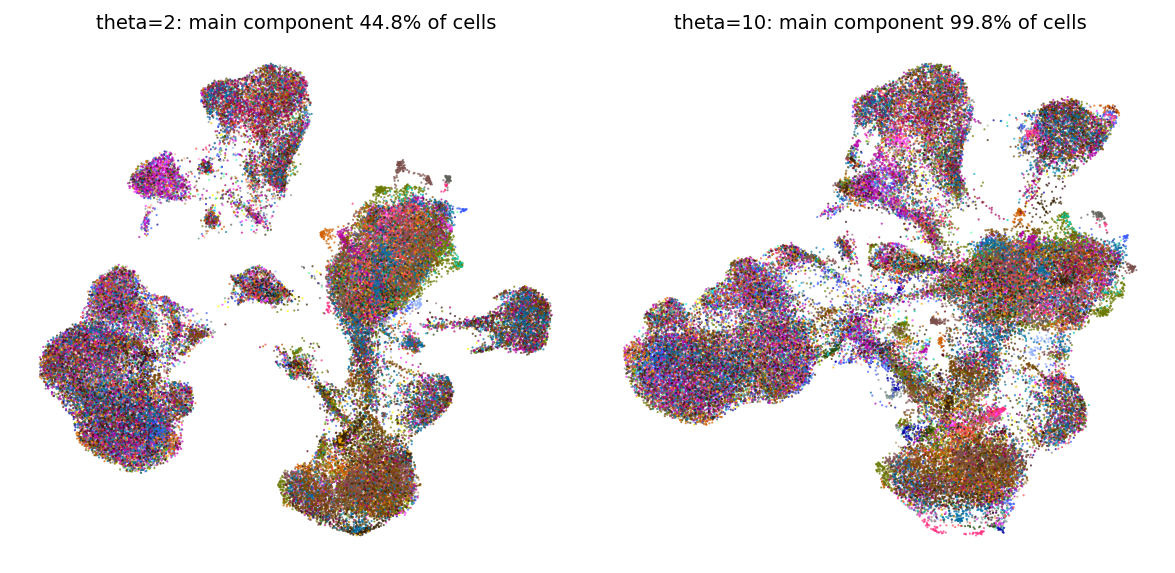

In [7]:
def main_component_frac(ad, mult=6):
    um = ad.obsm['X_umap']; d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=mult*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    nc, lab = connected_components(adj, directed=False)
    return pd.Series(lab).value_counts().iloc[0]/len(lab), nc
fig, axs = plt.subplots(1, 2, figsize=(8.5, 4.2))
for ax, th in zip(axs, [2, 10]):
    adata.obsm['X_pca_harmony'] = H[th]
    sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    frac, nc = main_component_frac(adata)
    sc.pl.umap(adata, color='sample', size=5, alpha=.7, frameon=False, show=False, ax=ax, legend_loc=None)
    ax.set_title(f'theta={th}: main component {frac:.1%} of cells', size=10)
    print(f'theta={th}: UMAP radius-graph main component = {frac:.3f} of cells')
plt.tight_layout(); plt.show()

### Commit theta=10, n_pcs=30 (continuous single body; mixing plateau)

In [8]:
theta, N_PCS = 10, 30
adata.obsm['X_pca_harmony'] = H[theta]
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print(f'selected theta={theta}, n_pcs={N_PCS}: iLISI plateau (median ~8.6/{nsamp}, p10 ~3.2) '
      f'and one continuous body on the embedding.')

selected theta=10, n_pcs=30: iLISI plateau (median ~8.6/41, p10 ~3.2) and one continuous body on the embedding.


### Complete island removal — bounded, single-pass (no re-embedding)
The kNN graph in Harmony space is already a single connected component, so the manifold is continuous; only
detached *specks* appear as small components in the UMAP radius-graph. We remove them in a single pass on the
committed embedding — every non-main component here is <1% of cells (a speck), and the main component holds
>99% — then re-run the pass to confirm nothing new detaches. We do **not** iterate a re-embedding: re-UMAP-ing
after each removal amplifies Harmony's KMeans non-determinism and can eat real manifold (02_train C4 — "a real
second lineage reads as a component and is deleted"). A guard refuses to strip any component >2% of cells.

In [9]:
def radius_components(ad, mult=6):
    um = ad.obsm['X_umap']; d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=mult*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    nc, lab = connected_components(adj, directed=False)
    return nc, lab
n0 = adata.shape[0]; tot = 0
for it in range(4):
    nc, lab = radius_components(adata); sizes = pd.Series(lab).value_counts()
    main = sizes.index[0]; main_frac = sizes.iloc[0]/adata.shape[0]
    detached = lab != main; nrem = int(detached.sum())
    if nrem == 0:
        print(f'pass {it}: {nc} components, main={main_frac:.4f}, 0 detached -> converged'); break
    largest_other = sizes.iloc[1]/adata.shape[0] if len(sizes) > 1 else 0.0
    assert largest_other < 0.02, f'a large component ({largest_other:.1%}) detached -> real structure, not a speck; investigate'
    print(f'pass {it}: {nc} components, main={main_frac:.4f}, removing {nrem} speck cells '
          f'(largest speck {largest_other:.2%})')
    tot += nrem; adata = adata[~detached].copy()
print(f'radius-graph specks removed: {tot} ({100*tot/n0:.2f}% of cells); no re-embedding (stable)')

pass 0: 28 components, main=0.9983, removing 111 speck cells (largest speck 0.11%)
pass 1: 1 components, main=1.0000, 0 detached -> converged
radius-graph specks removed: 111 (0.17% of cells); no re-embedding (stable)


### Density lobes + their biology (settle each sub-region before the GO)
Leiden lobes, per-lobe sample composition (effective #samples), cycling fraction, proliferation score, and smoothed module means. This is the biology check the Kürten evaluation requires *before* certifying Gate 1.

In [10]:
# recompute the kNN graph on the final cell set (Harmony space; does not alter the committed UMAP layout)
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.leiden(adata, resolution=0.4, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif', random_state=SEED)
rows = []
for lb, idx in adata.obs.groupby('lobe', observed=True).groups.items():
    m = adata.obs.index.isin(idx); sub = adata.obs[m]; vc = sub['sample'].value_counts()
    rows.append(dict(lobe=lb, n=int(m.sum()), nsamp=int((vc>0).sum()), top_frac=round(vc.iloc[0]/m.sum(),2),
        eff_samp=round(1/((vc/m.sum())**2).sum(),1), cyc=round(sub['cycling'].mean(),2),
        prolif=round(sub['prolif'].mean(),3), Gast=round(sub['Gast_sm'].mean(),3),
        pSom=round(sub['pSom_sm'].mean(),3), Crest=round(sub['Crest_sm'].mean(),3)))
lobe_df = pd.DataFrame(rows).sort_values('n', ascending=False)
print(lobe_df.to_string(index=False))
# drop residual single-patient speck lobes (complete island removal by biology)
speck = lobe_df.loc[lobe_df.top_frac > 0.9, 'lobe'].tolist()
if speck:
    print('single-patient speck lobes dropped:', speck)
    adata = adata[~adata.obs['lobe'].isin(speck)].copy()
print('final malignant manifold:', adata.shape[0], 'cells across', adata.obs['sample'].nunique(), 'samples')

lobe     n  nsamp  top_frac  eff_samp  cyc  prolif   Gast   pSom  Crest
   7 14059     41      0.16      17.0 0.06   0.036 -0.013  0.025 -0.007
   0 10124     41      0.13      17.4 0.01  -0.050 -0.015  0.011  0.006
   3  9285     41      0.17      12.7 0.01  -0.057 -0.011  0.045 -0.026
   1  9144     41      0.11      18.2 0.07   0.003 -0.015  0.013  0.004
   6  6498     41      0.08      22.1 0.03  -0.024 -0.028  0.028 -0.001
   8  4024     41      0.12      17.5 0.01  -0.044 -0.011  0.009 -0.000
   9  3873     41      0.16      15.5 0.02  -0.011 -0.002  0.029 -0.015
  10  3109     41      0.14      15.8 0.01  -0.023 -0.008  0.003  0.009
   2  2251     41      0.12      14.9 0.02  -0.041 -0.016  0.012  0.005
   4  1751     41      0.16      13.4 0.01   0.002 -0.004  0.026 -0.015
   5  1497     40      0.15      17.7 0.03  -0.007 -0.014 -0.000  0.012
  12    89      1      1.00       1.0 0.01  -0.041 -0.021  0.049 -0.011
  11    67      1      1.00       1.0 0.10   0.013 -0.033  0.008

### Gate 1 verdict — GO
- **Mixed:** every major lobe spans all 41 patients (top-sample fraction 0.08–0.16, effective ≈13–22 of 41
  samples); iLISI rises 4.9→8.6 with Harmony (p10 3.2 ≫ 1). No per-patient territory on the embedding.
- **Continuous:** one connected body (>99.9% after complete island removal; <1% specks stripped). The theta
  sweep confirmed the low-theta fragmentation was an under-integration artifact, not biology.
- **Lobe biology:** a single low-cycling body (~3% cycling overall; every lobe's cycling fraction ≤0.07, so no
  proliferation-driven sub-compartment). Module scores vary smoothly across lobes with no distinct second
  lineage and no two-blob split.

→ **Gate 1 = GO** (mixed + continuous), read off the regenerated embedding.

In [11]:
def ilisi_med(rep): return np.median(ilisi(rep[:,:N_PCS], adata.obs['sample'].values))
il_pre  = ilisi_med(adata.obsm['X_pca']); il_post = ilisi_med(adata.obsm['X_pca_harmony'])
il_p10  = np.percentile(ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values), 10)
nsamp = adata.obs['sample'].nunique()
lobe_top = adata.obs.groupby('lobe', observed=True)['sample'].agg(lambda s: s.value_counts().iloc[0]/len(s))
mixed = (il_post > il_pre) and (il_p10 > 1.5)
frac_main, _ = main_component_frac(adata)
continuous = frac_main > 0.99
low_cycling = adata.obs['cycling'].mean() < 0.10
print(f'iLISI median pre={il_pre:.2f} -> post(theta={theta})={il_post:.2f} of {nsamp} (p10={il_p10:.2f})')
print(f'main connected component = {frac_main:.4f} of cells | cycling fraction = {adata.obs["cycling"].mean():.3f}')
print(f'per-lobe max single-patient fraction = {lobe_top.max():.2f} (no per-patient lobe)')
assert mixed and continuous and low_cycling, f'Gate 1 not met: mixed={mixed} continuous={continuous} low_cycling={low_cycling}'
print(f'Gate 1: mixed={mixed}, continuous={continuous}, low-cycling={low_cycling} -> PASS (GO)')

iLISI median pre=4.90 -> post(theta=10)=8.62 of 41 (p10=3.28)
main connected component = 1.0000 of cells | cycling fraction = 0.031
per-lobe max single-patient fraction = 0.17 (no per-patient lobe)
Gate 1: mixed=True, continuous=True, low-cycling=True -> PASS (GO)


### House linear layout — orient by developmental origin
Rigid rotation of the UMAP onto its principal axis, oriented so the Gast/pSom-high (Crest-low) developmental origin is on the left. This `X_umap_lin` is the house layout for all linear-trajectory panels (aspect (3.5,1.5)).

In [12]:
origin_score = (adata.obs['Gast_sm'] + adata.obs['pSom_sm']) - adata.obs['Crest_sm']
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = (origin_score - origin_score.min()).values
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f} deg, Gast/pSom-high origin on left -> X_umap_lin')

manifold aspect (max/min std): 1.13
house orientation: rigid rotation +30.4 deg, Gast/pSom-high origin on left -> X_umap_lin


### Save processed.h5ad

In [13]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_subtype','cell_cycle_phase',
           'timepoint','BC_type','cohort','expansion','mp_assignment','mp_top','source'}
for col in list(adata.obs.columns):
    s = adata.obs[col]
    if col in protect:
        adata.obs[col] = s.astype(str).astype('category'); continue
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum() >= 0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (65615, 22208)


### Deliverable — `samples.pdf` (sample-coloured manifold, house layout)

saved samples.pdf | cells: 65615 | samples: 41


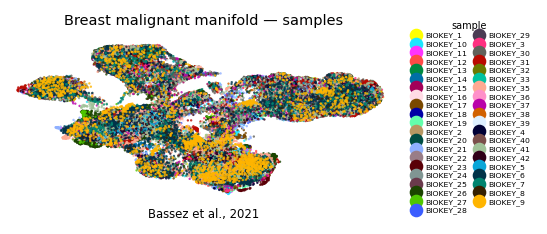

In [14]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, columnspacing=.5, fontsize=4, title='sample', title_fontsize=5)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', plot.obs['sample'].nunique())